# RACGAP1 in breast and ovarian cancer: a TCGA analysis

**Author:** Javan Boot, University of Nottingham

My undergraduate dissertation investigates proteins linked with DDR1 expression in breast and ovarian cancer,
with RACGAP1 (Rac GTPase-activating protein 1, a cytokinesis regulator) as my biomarker of interest.
This notebook asks related questions in public TCGA PanCancer Atlas data (via cBioPortal):

1. Does RACGAP1 mRNA expression differ between breast and ovarian tumours?
2. Does it differ between breast cancer PAM50 subtypes?
3. Which genes are co-expressed with RACGAP1, including DDR1?
4. Is RACGAP1 expression associated with overall survival?

In [11]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from pathlib import Path

API = "https://www.cbioportal.org/api"
STUDIES = {
    "Breast": "brca_tcga_pan_can_atlas_2018",
    "Ovarian": "ov_tcga_pan_can_atlas_2018",
}
GENES = ["RACGAP1", "DDR1", "PPP1R1B", "LIG3", "KIF23", "SHCBP1", "PLK1", "KIF11", "ECT2", "CDC42", "ANLN", "PRC1", "KIF20A"]

Path("data").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
sns.set_theme(style="ticks")

## 2. Download the data from cBioPortal
cBioPortal stores genes by Entrez ID, so first convert gene symbols to Entrez IDs using the cBioPortal API.

In [12]:
response = requests.post(f"{API}/genes/fetch",
                         params={"geneIdType": "HUGO_GENE_SYMBOL"},
                         json=GENES)
response.raise_for_status()
gene_table = pd.DataFrame(response.json())[["hugoGeneSymbol", "entrezGeneId"]]
print(gene_table)

   hugoGeneSymbol  entrezGeneId
0            ANLN         54443
1           CDC42           998
2            DDR1           780
3            ECT2          1894
4           KIF11          3832
5          KIF20A         10112
6           KIF23          9493
7            LIG3          3980
8            PLK1          5347
9         PPP1R1B         84152
10           PRC1          9055
11        RACGAP1         29127
12         SHCBP1         79801


In [3]:
all_expression = []
for cancer, study in STUDIES.items():
    url = f"{API}/molecular-profiles/{study}_rna_seq_v2_mrna/molecular-data/fetch"
    body = {
        "sampleListId": f"{study}_all",
        "entrezGeneIds": gene_table["entrezGeneId"].tolist(),
    }
    response = requests.post(url, json=body)
    response.raise_for_status()
    table = pd.DataFrame(response.json())
    table["cancer"] = cancer
    all_expression.append(table)
    print(cancer, "rows downloaded:", len(table))

expression_long = pd.concat(all_expression)
expression_long = expression_long[["cancer", "patientId", "sampleId", "entrezGeneId", "value"]]
expression_long.to_csv("data/expression_long.csv", index=False)

Breast rows downloaded: 14066
Ovarian rows downloaded: 3900


In [4]:
all_clinical = []
for cancer, study in STUDIES.items():
    response = requests.get(f"{API}/studies/{study}/clinical-data",
                            params={"clinicalDataType": "PATIENT", "pageSize": 100000})
    response.raise_for_status()
    table = pd.DataFrame(response.json())
    table = table.pivot(index="patientId", columns="clinicalAttributeId", values="value")
    table = table.reindex(columns=["SUBTYPE", "AGE", "OS_STATUS", "OS_MONTHS"])
    table["cancer"] = cancer
    all_clinical.append(table)
    print(cancer, "patients downloaded:", len(table))

clinical = pd.concat(all_clinical).reset_index()
clinical.to_csv("data/clinical.csv", index=False)

Breast patients downloaded: 1084
Ovarian patients downloaded: 585


## 3. Clean and combine
Reshape expression to one row per tumour, log2-transform it, keep one tumour per patient,
and join it to the clinical data by patient ID.

In [5]:
expression_long = pd.read_csv("data/expression_long.csv")
clinical = pd.read_csv("data/clinical.csv")

id_to_symbol = dict(zip(gene_table["entrezGeneId"], gene_table["hugoGeneSymbol"]))
expression_long["gene"] = expression_long["entrezGeneId"].map(id_to_symbol)

expression = expression_long.pivot_table(index=["cancer", "patientId", "sampleId"],
                                         columns="gene", values="value").reset_index()
expression = expression.drop_duplicates(subset="patientId")
expression[GENES] = np.log2(expression[GENES] + 1)

data = expression.merge(clinical.drop(columns="cancer"), on="patientId", how="left")
data["OS_MONTHS"] = pd.to_numeric(data["OS_MONTHS"], errors="coerce")
data["died"] = data["OS_STATUS"].str.startswith("1").astype(float)
data.loc[data["OS_STATUS"].isna(), "died"] = np.nan
data.to_csv("data/clean_data.csv", index=False)
print(data.shape)
print(data.groupby("cancer")["RACGAP1"].describe())

(1382, 21)
          count       mean       std       min       25%        50%  \
cancer                                                                
Breast   1082.0   9.737305  0.900080  7.132155  9.120775   9.766737   
Ovarian   300.0  10.286013  0.739341  7.495100  9.853071  10.365064   

               75%        max  
cancer                         
Breast   10.412885  12.462640  
Ovarian  10.751014  11.950766  


## 4. Results
### 4.1 RACGAP1 expression in breast vs ovarian tumours
Expression values are not normally distributed, so I compare groups with the non-parametric
Mann-Whitney U test (equivalent to the Wilcoxon rank-sum test in R or SPSS).

Breast median: 9.766736736280192 Ovarian median: 10.36506401987883 p = 3.557932175440954e-22


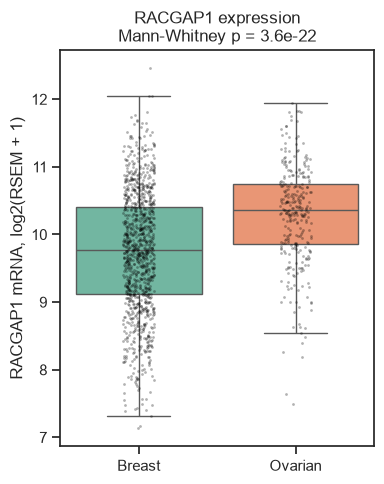

In [6]:
fig, ax = plt.subplots(figsize=(4, 5))
sns.boxplot(data=data, x="cancer", y="RACGAP1", hue="cancer", palette="Set2", showfliers=False, ax=ax)
sns.stripplot(data=data, x="cancer", y="RACGAP1", color="black", size=2, alpha=0.3, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("RACGAP1 mRNA, log2(RSEM + 1)")
breast = data.loc[data["cancer"] == "Breast", "RACGAP1"]
ovarian = data.loc[data["cancer"] == "Ovarian", "RACGAP1"]
u, p = stats.mannwhitneyu(breast, ovarian)
ax.set_title(f"RACGAP1 expression\nMann-Whitney p = {p:.2g}")
fig.tight_layout()
fig.savefig("figures/fig1_racgap1_breast_vs_ovarian.png", dpi=300)
print("Breast median:", breast.median(), "Ovarian median:", ovarian.median(), "p =", p)

### 4.2 RACGAP1 across breast cancer PAM50 subtypes
Kruskal-Wallis test (non-parametric version of one-way ANOVA) across the five subtypes.

             count     median
SUBTYPE                      
BRCA_Basal     171  10.265017
BRCA_Her2       78  10.248152
BRCA_LumA      499   9.329915
BRCA_LumB      197  10.519174
BRCA_Normal     36   8.897539


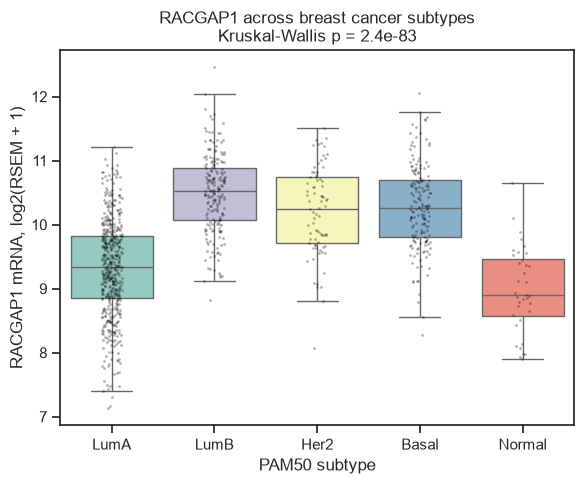

In [7]:
subtype_order = ["BRCA_LumA", "BRCA_LumB", "BRCA_Her2", "BRCA_Basal", "BRCA_Normal"]
breast_data = data[(data["cancer"] == "Breast") & data["SUBTYPE"].isin(subtype_order)]
groups = [breast_data.loc[breast_data["SUBTYPE"] == s, "RACGAP1"] for s in subtype_order]
h, p = stats.kruskal(*groups)
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=breast_data, x="SUBTYPE", y="RACGAP1", order=subtype_order,
            hue="SUBTYPE", palette="Set3", showfliers=False, ax=ax)
sns.stripplot(data=breast_data, x="SUBTYPE", y="RACGAP1", order=subtype_order,
              color="black", size=2, alpha=0.3, ax=ax)
ax.set_xticks(range(len(subtype_order)))
ax.set_xticklabels([s.replace("BRCA_", "") for s in subtype_order])
ax.set_xlabel("PAM50 subtype")
ax.set_ylabel("RACGAP1 mRNA, log2(RSEM + 1)")
ax.set_title(f"RACGAP1 across breast cancer subtypes\nKruskal-Wallis p = {p:.2g}")
fig.tight_layout()
fig.savefig("figures/fig2_racgap1_breast_subtypes.png", dpi=300)
print(breast_data.groupby("SUBTYPE")["RACGAP1"].agg(["count", "median"]))

### 4.3 Genes co-expressed with RACGAP1
Spearman rank correlation between RACGAP1 and each gene in the panel, separately in each cancer.

     cancer     gene       rho              p
1    Breast  PPP1R1B -0.157242   2.006975e-07
8    Breast    CDC42  0.002029   9.468466e-01
0    Breast     DDR1  0.041160   1.760799e-01
2    Breast     LIG3  0.188153   4.441020e-10
4    Breast   SHCBP1  0.734906  2.307512e-184
7    Breast     ECT2  0.773168  7.980329e-216
9    Breast     ANLN  0.785909  1.039364e-227
5    Breast     PLK1  0.792094  8.887377e-234
11   Breast   KIF20A  0.793630  2.568622e-235
10   Breast     PRC1  0.804480  1.420683e-246
3    Breast    KIF23  0.837163  2.810824e-285
6    Breast    KIF11  0.845411  2.016931e-296
12  Ovarian     DDR1 -0.065826   2.556995e-01
13  Ovarian  PPP1R1B -0.065807   2.558411e-01
20  Ovarian    CDC42  0.115574   4.548449e-02
14  Ovarian     LIG3  0.162084   4.888625e-03
16  Ovarian   SHCBP1  0.473115   3.868119e-18
21  Ovarian     ANLN  0.605021   2.434056e-31
18  Ovarian    KIF11  0.638847   8.303486e-36
22  Ovarian     PRC1  0.674122   4.202754e-41
23  Ovarian   KIF20A  0.679853   4

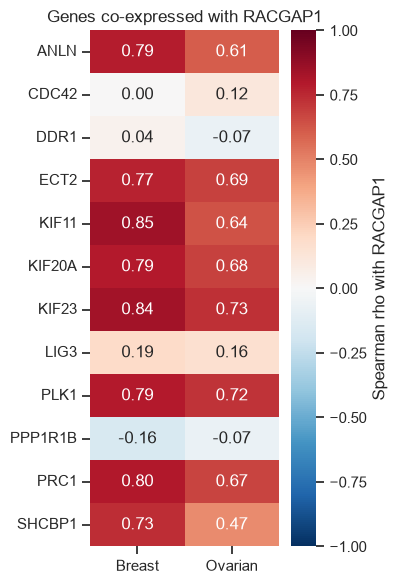

In [8]:
results = []
for cancer in STUDIES:
    subset = data[data["cancer"] == cancer]
    for gene in GENES:
        if gene == "RACGAP1":
            continue
        rho, p = stats.spearmanr(subset["RACGAP1"], subset[gene], nan_policy="omit")
        results.append({"cancer": cancer, "gene": gene, "rho": rho, "p": p})
correlations = pd.DataFrame(results)
correlations.to_csv("data/racgap1_correlations.csv", index=False)
print(correlations.sort_values(["cancer", "rho"]))

rho_table = correlations.pivot(index="gene", columns="cancer", values="rho")
fig, ax = plt.subplots(figsize=(4, 6))
sns.heatmap(rho_table, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Spearman rho with RACGAP1"})
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Genes co-expressed with RACGAP1")
fig.tight_layout()
fig.savefig("figures/fig3_racgap1_correlations.png", dpi=300)

### 4.4 RACGAP1 expression and overall survival
Patients are split at the median RACGAP1 value into "high" and "low" groups.
Kaplan-Meier curves are compared with the log-rank test.

Breast log-rank p = 0.05423882316272799
Ovarian log-rank p = 0.5803018287297181


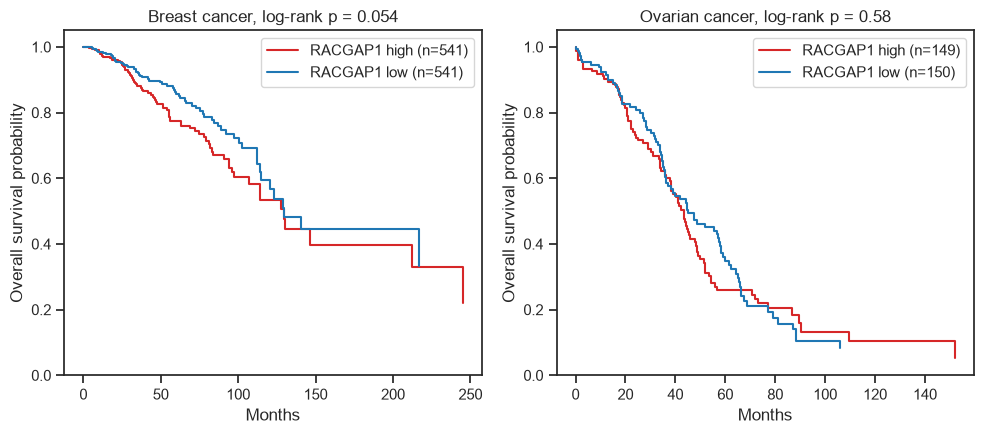

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, cancer in zip(axes, STUDIES):
    subset = data[data["cancer"] == cancer].dropna(subset=["OS_MONTHS", "died", "RACGAP1"])
    cutoff = subset["RACGAP1"].median()
    subset = subset.assign(group=np.where(subset["RACGAP1"] > cutoff, "RACGAP1 high", "RACGAP1 low"))
    for group_name, colour in [("RACGAP1 high", "tab:red"), ("RACGAP1 low", "tab:blue")]:
        g = subset[subset["group"] == group_name]
        km = SurvfuncRight(g["OS_MONTHS"], g["died"])
        times = np.concatenate([[0], km.surv_times])
        probs = np.concatenate([[1], km.surv_prob])
        ax.step(times, probs, where="post", color=colour, label=f"{group_name} (n={len(g)})")
    chisq, p = survdiff(subset["OS_MONTHS"], subset["died"], subset["group"])
    ax.set_title(f"{cancer} cancer, log-rank p = {p:.2g}")
    ax.set_xlabel("Months")
    ax.set_ylabel("Overall survival probability")
    ax.set_ylim(0, 1.05)
    ax.legend()
    print(cancer, "log-rank p =", p)
fig.tight_layout()
fig.savefig("figures/fig4_racgap1_survival.png", dpi=300)

## 5. Conclusions

**1. Breast vs ovarian.** RACGAP1 was higher in ovarian tumours than breast tumours (median 10.37 vs 9.77, about 1.5 times higher; Mann-Whitney p = 3.6 × 10⁻²²). This makes sense because TCGA ovarian tumours are high-grade serous cancers, which divide quickly. Breast cancer includes many slow-growing tumours. The two groups come from different studies, so this is a rough comparison.

**2. Breast cancer subtypes.** RACGAP1 was very different between subtypes (Kruskal-Wallis p = 2.4 × 10⁻⁸³). It was highest in Luminal B (median 10.52), then Basal-like (10.27) and HER2-enriched (10.25). It was lowest in Luminal A (9.33) and Normal-like (8.90). The fast-growing subtypes had the most RACGAP1, which fits its role in cell division.

**3. Co-expression.** RACGAP1 rose and fell together with cell-division genes in both cancers. The strongest links were KIF11, KIF23, PRC1, PLK1, KIF20A, ANLN, ECT2 and SHCBP1 (rho 0.73 to 0.85 in breast, 0.47 to 0.73 in ovarian). This relates to what we know: RACGAP1 works with KIF23 and ECT2 to split cells in two during cytokinesis. DDR1, CDC42, LIG3 and PPP1R1B showed little or no link with RACGAP1 (rho between -0.16 and 0.19).

**4. Survival.** In breast cancer, patients with high RACGAP1 on average had a reduced survival, but this was not statistically significant (log-rank p = 0.054). In ovarian cancer there was no difference (p = 0.58).

**5. Link to my dissertation.** RACGAP1 and DDR1 do not rise and fall together at the mRNA level (rho = 0.04 in breast, -0.07 in ovarian). Any link between them may happen at the protein level, for example in how much protein is made, where it sits in the cell, or how active it is. In my dissertation I am studying RACGAP1 protein in breast and ovarian patient samples using Western blotting and immunohistochemistry, which will test whether they are linked at the protein level.

### Limitations
- **mRNA is not protein.** TCGA measures RNA, but my lab work measures protein. RACGAP1's activity also depends on where it is in the cell and on phosphorylation.
- **Cell division may explain a lot.** RACGAP1 goes up whenever cells divide more, so some of these results may simply reflect how fast the tumour is growing or how many of its cells were dividing when the sample was taken.
- **Mixed samples.** Each tumour sample contains cancer cells, normal cells and immune cells, which reduces validity: the results reflect the whole sample, not just the cancer cells.
- **Median split.** I used the median as the cut point for high vs low RACGAP1. This choice is arbitrary, and a different cut point could change the result.
- **No adjustment.** The survival analysis did not take stage, age or subtype into account.
- **Correlation is not causation.** Genes moving together does not mean one controls the other.

In [14]:
readme = """# RACGAP1 in Breast and Ovarian Cancer: a TCGA Analysis in Python

An analysis of RACGAP1 gene expression in 1,082 breast and 300 ovarian tumours from The Cancer Genome Atlas (TCGA). It links to my undergraduate dissertation on proteins linked with DDR1 in breast and ovarian cancer, where RACGAP1 is my biomarker of interest.

## Background
RACGAP1 is a protein that helps cells split in two at the end of cell division (cytokinesis). It works with KIF23 and ECT2. High RACGAP1 has been linked to more aggressive cancers. In my dissertation (University of Nottingham) I study RACGAP1 and DDR1 protein in patient samples using Western blotting and immunohistochemistry. This project asks what large public patient datasets show.

## Questions
1. Is RACGAP1 different between breast and ovarian tumours?
2. Is it different between breast cancer subtypes?
3. Which genes rise and fall with RACGAP1, including DDR1?
4. Is RACGAP1 linked to survival?

## Data
- **Source:** TCGA PanCancer Atlas, downloaded with the [cBioPortal](https://www.cbioportal.org) API (`brca_tcga_pan_can_atlas_2018`, `ov_tcga_pan_can_atlas_2018`).
- **Expression:** RNA sequencing (RSEM), log2-transformed. One tumour per patient.
- **Clinical:** breast cancer subtype (PAM50), survival time and status.
- **Genes:** RACGAP1, DDR1, PPP1R1B, LIG3, KIF23, SHCBP1, PLK1, KIF11, ECT2, CDC42, ANLN, PRC1, KIF20A.

## Methods
- Downloading and cleaning data: `requests`, `pandas`
- Comparing groups: Mann-Whitney U and Kruskal-Wallis tests (`scipy`)
- Co-expression: Spearman correlation (`scipy`)
- Survival: median split, Kaplan-Meier curves and log-rank test (`statsmodels`)
- Figures: `matplotlib`, `seaborn`

## Key results
| Figure | Finding |
|---|---|
| IMG[](figures/fig1_racgap1_breast_vs_ovarian.png) | RACGAP1 was higher in ovarian than breast tumours (median 10.37 vs 9.77, p = 3.6 × 10⁻²²). |
| IMG[](figures/fig2_racgap1_breast_subtypes.png) | RACGAP1 was highest in the fast-growing subtypes (Luminal B, Basal-like, HER2) and lowest in Luminal A and Normal-like (p = 2.4 × 10⁻⁸³). |
| IMG[](figures/fig3_racgap1_correlations.png) | RACGAP1 rose and fell strongly with cell-division genes such as KIF11, KIF23 and PRC1 (rho up to 0.85), but not with DDR1 (rho = 0.04 breast, -0.07 ovarian). |
| IMG[](figures/fig4_racgap1_survival.png) | High RACGAP1 showed a non-significant trend towards poorer survival in breast cancer (p = 0.054) and no difference in ovarian cancer (p = 0.58). |

## Limitations
- RNA levels do not always match protein levels or activity.
- RACGAP1 rises with cell division, so some results may reflect how fast tumours grow.
- Each sample mixes cancer, normal and immune cells.
- The median cut point is arbitrary.
- Survival was not adjusted for stage, age or subtype.

## Next steps
- Compare with my protein results from Western blotting and immunohistochemistry.
- Adjust survival for stage, age and subtype using a Cox regression model.

## How to run
1. Install [Anaconda](https://www.anaconda.com/download), or run `pip install -r requirements.txt`.
2. Download this repository and open `racgap1_analysis.ipynb` in Jupyter.
3. Click **Run All**. The data downloads automatically into `data/`, and figures are saved in `figures/`.

## Acknowledgements
Data from The Cancer Genome Atlas (TCGA) Research Network, accessed through cBioPortal (Cerami et al., *Cancer Discovery* 2012; Gao et al., *Science Signaling* 2013).

## Author
Javan Boot, MSci Cancer Sciences, University of Nottingham
"""

readme = readme.replace("IMG[", "!" + "[")
open("README.md", "w").write(readme)
print("README saved")

README saved
